# RAG and Agentic RAG with LangChain + LangGraph - Ollama Local LLM Version


'''
Before running the notebook locally, open a terminal and run:

```bash
ollama pull llama3.2
ollama pull nomic-embed-text
ollama serve
```
    
If you prefer another local model, change `LLM_MODEL` and `EMBEDDING_MODEL` in the setup cell.
'''

In [1]:
# Install dependencies
# Run this once at the beginning of the notebook.

#!pip install -U langchain langchain-community langgraph langchain-ollama faiss-cpu python-dotenv

In [2]:
# Create local Ollama LLM and embedding model

from langchain_ollama import ChatOllama, OllamaEmbeddings

# Make sure these models are available locally:
#   ollama pull llama3.2
#   ollama pull nomic-embed-text

LLM_MODEL = "llama3.2"

EMBEDDING_MODEL = "nomic-embed-text"

# Local chat model for answering, routing, and generation.

llm = ChatOllama(
    model=LLM_MODEL,
    temperature=0
)

# Local embedding model for converting text chunks into vectors.
embedding_model = OllamaEmbeddings(
    model=EMBEDDING_MODEL
)

print("Ollama LLM and embedding model initialized.")
print("LLM model:", LLM_MODEL)
print("Embedding model:", EMBEDDING_MODEL)

Ollama LLM and embedding model initialized.
LLM model: llama3.2
Embedding model: nomic-embed-text


In [3]:
# Quick Ollama connection test
# If this cell fails, make sure Ollama is installed and running.

response = llm.invoke("Reply with exactly: Ollama is working")
print(response.content)

Ollama is working


In [4]:
from langchain_core.documents import Document

# Synthetic company onboarding knowledge base for the exercise.
# In a real project, these documents could come from PDFs, SharePoint, Confluence, Notion, websites, or HR systems.

documents = [
    Document(
        page_content="""
        Remote Work Policy:
        Employees are allowed to work remotely up to two days per week.
        Remote work must be coordinated with the direct manager.
        Employees must remain available during core working hours from 10:00 AM to 4:00 PM.
        Fully remote work requires approval from the department head.
        """,
        metadata={"source": "remote_work_policy"}
    ),
    Document(
        page_content="""
        Leave Policy:
        Full-time employees receive 22 annual leave days per year.
        Sick leave must be reported to the direct manager as early as possible.
        For sick leave longer than two consecutive days, a medical certificate is required.
        Unused annual leave can be carried forward for a maximum of five days.
        """,
        metadata={"source": "leave_policy"}
    ),
    Document(
        page_content="""
        Business Travel Policy:
        Business travel must be approved by the employee's direct manager and the finance department.
        Employees should submit travel requests at least ten working days before the planned trip.
        Economy class is required for flights shorter than six hours.
        Hotel bookings should follow the approved corporate travel list.
        """,
        metadata={"source": "business_travel_policy"}
    ),
    Document(
        page_content="""
        Equipment Request Process:
        Employees can request laptops, monitors, keyboards, and other work equipment through the IT service portal.
        The request must include a business justification.
        The employee's manager must approve the request before IT processes it.
        Standard equipment requests are usually completed within five working days.
        """,
        metadata={"source": "equipment_policy"}
    ),
    Document(
        page_content="""
        Password Reset Policy:
        Employees who forget their password should use the self-service password reset portal.
        If the portal does not work, they should contact the IT helpdesk.
        Passwords must not be shared with colleagues or managers.
        Multi-factor authentication is required for all company systems.
        """,
        metadata={"source": "password_policy"}
    ),
    Document(
        page_content="""
        Expense Reimbursement Policy:
        Employees must submit reimbursement claims within 30 days of the expense date.
        Receipts are required for all expenses above 25 dollars.
        Claims must be approved by the direct manager and finance team.
        """,
        metadata={"source": "expense_policy"}
    ),
    Document(
        page_content="""
        Training and Development Policy:
        Employees may request professional training related to their role.
        Training requests must include the course name, provider, cost, and expected business benefit.
        Requests require approval from the direct manager and HR.
        """,
        metadata={"source": "training_policy"}
    )
]

print(f"Loaded {len(documents)} source documents.")

Loaded 7 source documents.


In [5]:
#!pip install langchain-text-splitters

In [6]:
# =========================================================
# 1. Split documents into chunks
# =========================================================
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50,
    length_function=len,
    separators=["\n\n", "\n", " ", ""]
)

chunks = text_splitter.split_documents(documents)

print(f"Split {len(documents)} documents into {len(chunks)} chunks.")
for i, chunk in enumerate(chunks[:5], start=1):
    print(f"\nChunk {i} (source: {chunk.metadata.get('source')}):")
    print(chunk.page_content[:200])

Split 7 documents into 12 chunks.

Chunk 1 (source: remote_work_policy):
Remote Work Policy:
        Employees are allowed to work remotely up to two days per week.
        Remote work must be coordinated with the direct manager.
        Employees must remain available dur

Chunk 2 (source: remote_work_policy):
Fully remote work requires approval from the department head.

Chunk 3 (source: leave_policy):
Leave Policy:
        Full-time employees receive 22 annual leave days per year.
        Sick leave must be reported to the direct manager as early as possible.
        For sick leave longer than two 

Chunk 4 (source: leave_policy):
Unused annual leave can be carried forward for a maximum of five days.

Chunk 5 (source: business_travel_policy):
Business Travel Policy:
        Business travel must be approved by the employee's direct manager and the finance department.
        Employees should submit travel requests at least ten working days 


In [7]:
# =========================================================
# 2. Create FAISS vector store and retriever
# =========================================================
from langchain_community.vectorstores import FAISS

vectorstore = FAISS.from_documents(
    documents=chunks,
    embedding=embedding_model
)

retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 3}
)

print(f"Created FAISS vector store with {vectorstore.index.ntotal} vectors.")

/var/folders/g4/szxdx3r92fb3fflz45r3pwrr0000gn/T/ipykernel_73360/648423523.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Created FAISS vector store with 12 vectors.


In [8]:
# =========================================================
# 3. Helper function to format retrieved chunks
# =========================================================
def format_retrieved_chunks(chunks):
    """Format retrieved documents for use in an LLM prompt."""
    formatted = []

    for i, chunk in enumerate(chunks, start=1):
        source = chunk.metadata.get("source", "unknown")
        formatted.append(f"[Source {i}: {source}]\n{chunk.page_content.strip()}")

    return "\n\n".join(formatted)

print("Retrieved-chunk formatting helper created.")

Retrieved-chunk formatting helper created.


In [9]:
# =========================================================
# 4. Test retrieval before using the LLM
# =========================================================
retrieval_question = "How many days per week can employees work remotely?"

retrieved_chunks = retriever.invoke(retrieval_question)

print("QUESTION:", retrieval_question)
print("\nRETRIEVED CONTEXT:")
print(format_retrieved_chunks(retrieved_chunks))

print("\nNumber of chunks retrieved:", len(retrieved_chunks))

QUESTION: How many days per week can employees work remotely?

RETRIEVED CONTEXT:
[Source 1: remote_work_policy]
Remote Work Policy:
        Employees are allowed to work remotely up to two days per week.
        Remote work must be coordinated with the direct manager.
        Employees must remain available during core working hours from 10:00 AM to 4:00 PM.

[Source 2: remote_work_policy]
Fully remote work requires approval from the department head.

[Source 3: leave_policy]
Leave Policy:
        Full-time employees receive 22 annual leave days per year.
        Sick leave must be reported to the direct manager as early as possible.
        For sick leave longer than two consecutive days, a medical certificate is required.

Number of chunks retrieved: 3


In [10]:
# =========================================================
# 5. Build Classic RAG chain
# =========================================================
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

In [11]:
classic_rag_prompt = ChatPromptTemplate.from_template("""
Answer the question using only the provided context.
If the answer is not present in the context, say that you do not know.

Context:
{context}

Question:
{question}
""")

rag_chain = (
    {
        "context": retriever | format_retrieved_chunks,
        "question": RunnablePassthrough()
    }
    | classic_rag_prompt
    | llm
    | StrOutputParser()
)

print("Classic RAG chain created.")

Classic RAG chain created.


In [12]:
# =========================================================
# 6. Test Classic RAG
# =========================================================
classic_questions = [
    "How many days per week can employees work remotely?",
    "Who approves business travel?",
    "How do I request a laptop?",
    "What is the company's bonus policy?"
]

for q in classic_questions:
    print("\n" + "="*80)
    print("QUESTION:", q)
    print("ANSWER:")
    print(rag_chain.invoke(q))


QUESTION: How many days per week can employees work remotely?
ANSWER:
According to Source 1: remote_work_policy, Employees are allowed to work remotely up to two days per week.

QUESTION: Who approves business travel?
ANSWER:
According to Source 1: business_travel_policy, business travel must be approved by two people:

1. The employee's direct manager
2. The finance department

QUESTION: How do I request a laptop?
ANSWER:
According to Source 1: equipment_policy, you can request laptops through the IT service portal. The request must also include a business justification, which will then be approved by your manager before being processed by IT.

QUESTION: What is the company's bonus policy?
ANSWER:
I don't know. The provided context does not mention anything about a bonus policy.


In [13]:
# =========================================================
# 7. Build Agentic RAG with LangGraph
# =========================================================
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

class AgentState(TypedDict):
    """Shared state passed between LangGraph nodes."""
    question: str
    route: str
    context: str
    answer: str

router_prompt = ChatPromptTemplate.from_template("""
You are a routing assistant.

Decide whether the user's question requires searching the company policy documents.

Return only one word:
- retrieve
- direct

Choose "retrieve" if the question is about:
remote work, leave, vacation, sick leave, travel, equipment, password, IT, approvals, company policies,
onboarding processes, expenses, reimbursement, training, development.

Choose "direct" if the question is:
a greeting, small talk, or a general question not requiring company documents.

User question:
{question}
""")



def route_question(state: AgentState):
    """Route policy questions to retrieval and general questions to direct generation."""
    route = (
        router_prompt
        | llm
        | StrOutputParser()
    ).invoke({"question": state["question"]})

    route = route.strip().lower()
    if "retrieve" in route:
        route = "retrieve"
    else:
        route = "direct"

    return {"route": route}



def decide_next_step(state: AgentState) -> Literal["retrieve", "direct"]:
    """Choose the next graph branch based on the router result."""
    return state["route"]



def retrieve_context(state: AgentState):
    """Retrieve relevant policy chunks and format them as context."""
    chunks = retriever.invoke(state["question"])
    context = format_retrieved_chunks(chunks)
    return {"context": context}

agentic_rag_prompt = ChatPromptTemplate.from_template("""
You are a helpful company onboarding assistant.

Use only the context below to answer the user's question.
Include the source name when possible.

If the answer is not in the context, say:
"I do not have enough information in the provided documents to answer this question."

Context:
{context}

Question:
{question}

Answer:
""")



def generate_rag_answer(state: AgentState):
    """Generate an answer grounded in retrieved policy context."""
    answer = (
        agentic_rag_prompt
        | llm
        | StrOutputParser()
    ).invoke({
        "context": state["context"],
        "question": state["question"]
    })
    return {"answer": answer}

direct_prompt = ChatPromptTemplate.from_template("""
You are a helpful AI assistant.
The user asked a question that does not require company policy retrieval.
Answer briefly and helpfully.

User question:
{question}

Answer:
""")



def generate_direct_answer(state: AgentState):
    """Generate a direct answer for questions that need no retrieval."""
    answer = (
        direct_prompt
        | llm
        | StrOutputParser()
    ).invoke({"question": state["question"]})
    return {"answer": answer}


In [14]:
# Build graph
agentic_rag_builder = StateGraph(AgentState)

agentic_rag_builder.add_node("route_question", route_question)
agentic_rag_builder.add_node("retrieve_context", retrieve_context)
agentic_rag_builder.add_node("generate_rag_answer", generate_rag_answer)
agentic_rag_builder.add_node("generate_direct_answer", generate_direct_answer)

agentic_rag_builder.add_edge(START, "route_question")
agentic_rag_builder.add_conditional_edges(
    "route_question",
    decide_next_step,
    {
        "retrieve": "retrieve_context",
        "direct": "generate_direct_answer"
    }
)
agentic_rag_builder.add_edge("retrieve_context", "generate_rag_answer")
agentic_rag_builder.add_edge("generate_rag_answer", END)
agentic_rag_builder.add_edge("generate_direct_answer", END)

agentic_rag_graph = agentic_rag_builder.compile()

print("Agentic RAG graph compiled.")

Agentic RAG graph compiled.


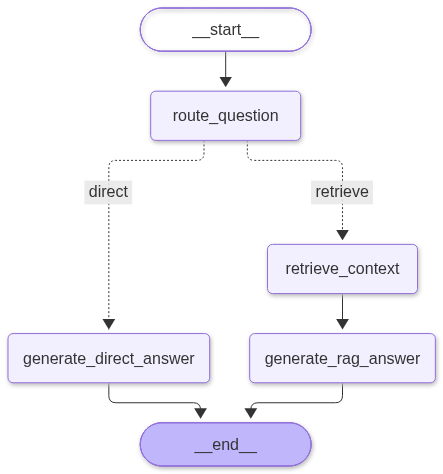

In [15]:
from IPython.display import Image, display

try:
    display(Image(agentic_rag_graph.get_graph().draw_mermaid_png()))
except Exception as error:
    print("PNG rendering is unavailable. Mermaid definition:")
    print(agentic_rag_graph.get_graph().draw_mermaid())
    print(f"\nRendering error: {error}")

In [16]:
# =========================================================
# 8. Test Agentic RAG
# =========================================================
def run_agentic_rag(question: str):
    """Run a question through the agentic RAG graph and print the result."""
    result = agentic_rag_graph.invoke({
        "question": question,
        "route": "",
        "context": "",
        "answer": ""
    })

    print("\n" + "=" * 80)
    print("QUESTION:", question)
    print("ROUTE:", result["route"])
    print("ANSWER:", result["answer"])
    return result

agentic_questions = [
    "Hi, what can you help me with?",
    "How many remote work days are allowed?",
    "Who approves reimbursement claims?",
    "What should I do if I forget my password?",
    "What is the company cafeteria menu?"
]

for q in agentic_questions:
    run_agentic_rag(q)


QUESTION: Hi, what can you help me with?
ROUTE: direct
ANSWER: I'd be happy to help you with any questions or topics you'd like to discuss. What's on your mind? Do you need help with a problem, want information on a particular subject, or just need someone to chat with? I'm here to assist you!

QUESTION: How many remote work days are allowed?
ROUTE: retrieve
ANSWER: According to our company's Remote Work Policy (Source 1), employees are allowed to work remotely up to two days per week.

QUESTION: Who approves reimbursement claims?
ROUTE: retrieve
ANSWER: According to Source 1: expense_policy, Claims must be approved by the direct manager and finance team.

QUESTION: What should I do if I forget my password?
ROUTE: retrieve
ANSWER: According to our company's policy, if you forget your password, you should use the self-service password reset portal. If the portal does not work, you should contact the IT helpdesk for assistance. (Source: [password_policy])

QUESTION: What is the company 

In [17]:
# =========================================================
# 9. Optional: show retrieved context for a policy question
# =========================================================
result = run_agentic_rag("How do I request professional training?")
print("\nRetrieved context used by the agent:\n")
print(result["context"])


QUESTION: How do I request professional training?
ROUTE: retrieve
ANSWER: To request professional training, you will need to submit a formal request that includes the course name, provider, cost, and expected business benefit. Your direct manager must approve your request, and HR approval is also required.

Retrieved context used by the agent:

[Source 1: training_policy]
Training and Development Policy:
        Employees may request professional training related to their role.
        Training requests must include the course name, provider, cost, and expected business benefit.
        Requests require approval from the direct manager and HR.

[Source 2: equipment_policy]
Equipment Request Process:
        Employees can request laptops, monitors, keyboards, and other work equipment through the IT service portal.
        The request must include a business justification.
        The employee's manager must approve the request before IT processes it.

[Source 3: equipment_policy]
Stand